# Create a World

Build a world with pyotter: load a map template, look at its road graph, assign hazard probabilities to segments, then save and reload it.

In [1]:
from pathlib import Path

from pyotter import World
from pyotter.core import WorldHazardLibrary, WorldRoadGraph

OUTPUT = Path("runs")
OUTPUT.mkdir(exist_ok=True)

## Hazard Library

A condition holds on a segment for the whole run, and its probability is the chance that it is present. An event happens at a moment, and its probability is the chance per second that one starts.

In [2]:
hazards = WorldHazardLibrary()

for hazard in hazards:
    print(f"{hazard.id:16} {hazard.kind.value:10} {hazard.description}")

pedestrian       event      A pedestrian is on or entering the roadway
low_visibility   condition  Detection range is reduced
wet_road         condition  Tire friction is reduced


## Road Graph

A template is a road graph with no hazard probabilities assigned.

In [3]:
wrg = WorldRoadGraph.from_template("town10")

segments = wrg.get_segments()
print(f"{wrg.map_name}: {len(segments)} segments, {len(wrg.spawn_points)} spawn points")

Town10HD_Opt: 168 segments, 155 spawn points


`view_topology` returns a matplotlib `Figure` with axes in meters. `LABEL_SEGMENTS` prints each segment ID along its lane; the labelled figure is larger, so open or zoom the image to read the IDs. `SHOW_JUNCTIONS` outlines each junction's bounding box and tags it with its ID.

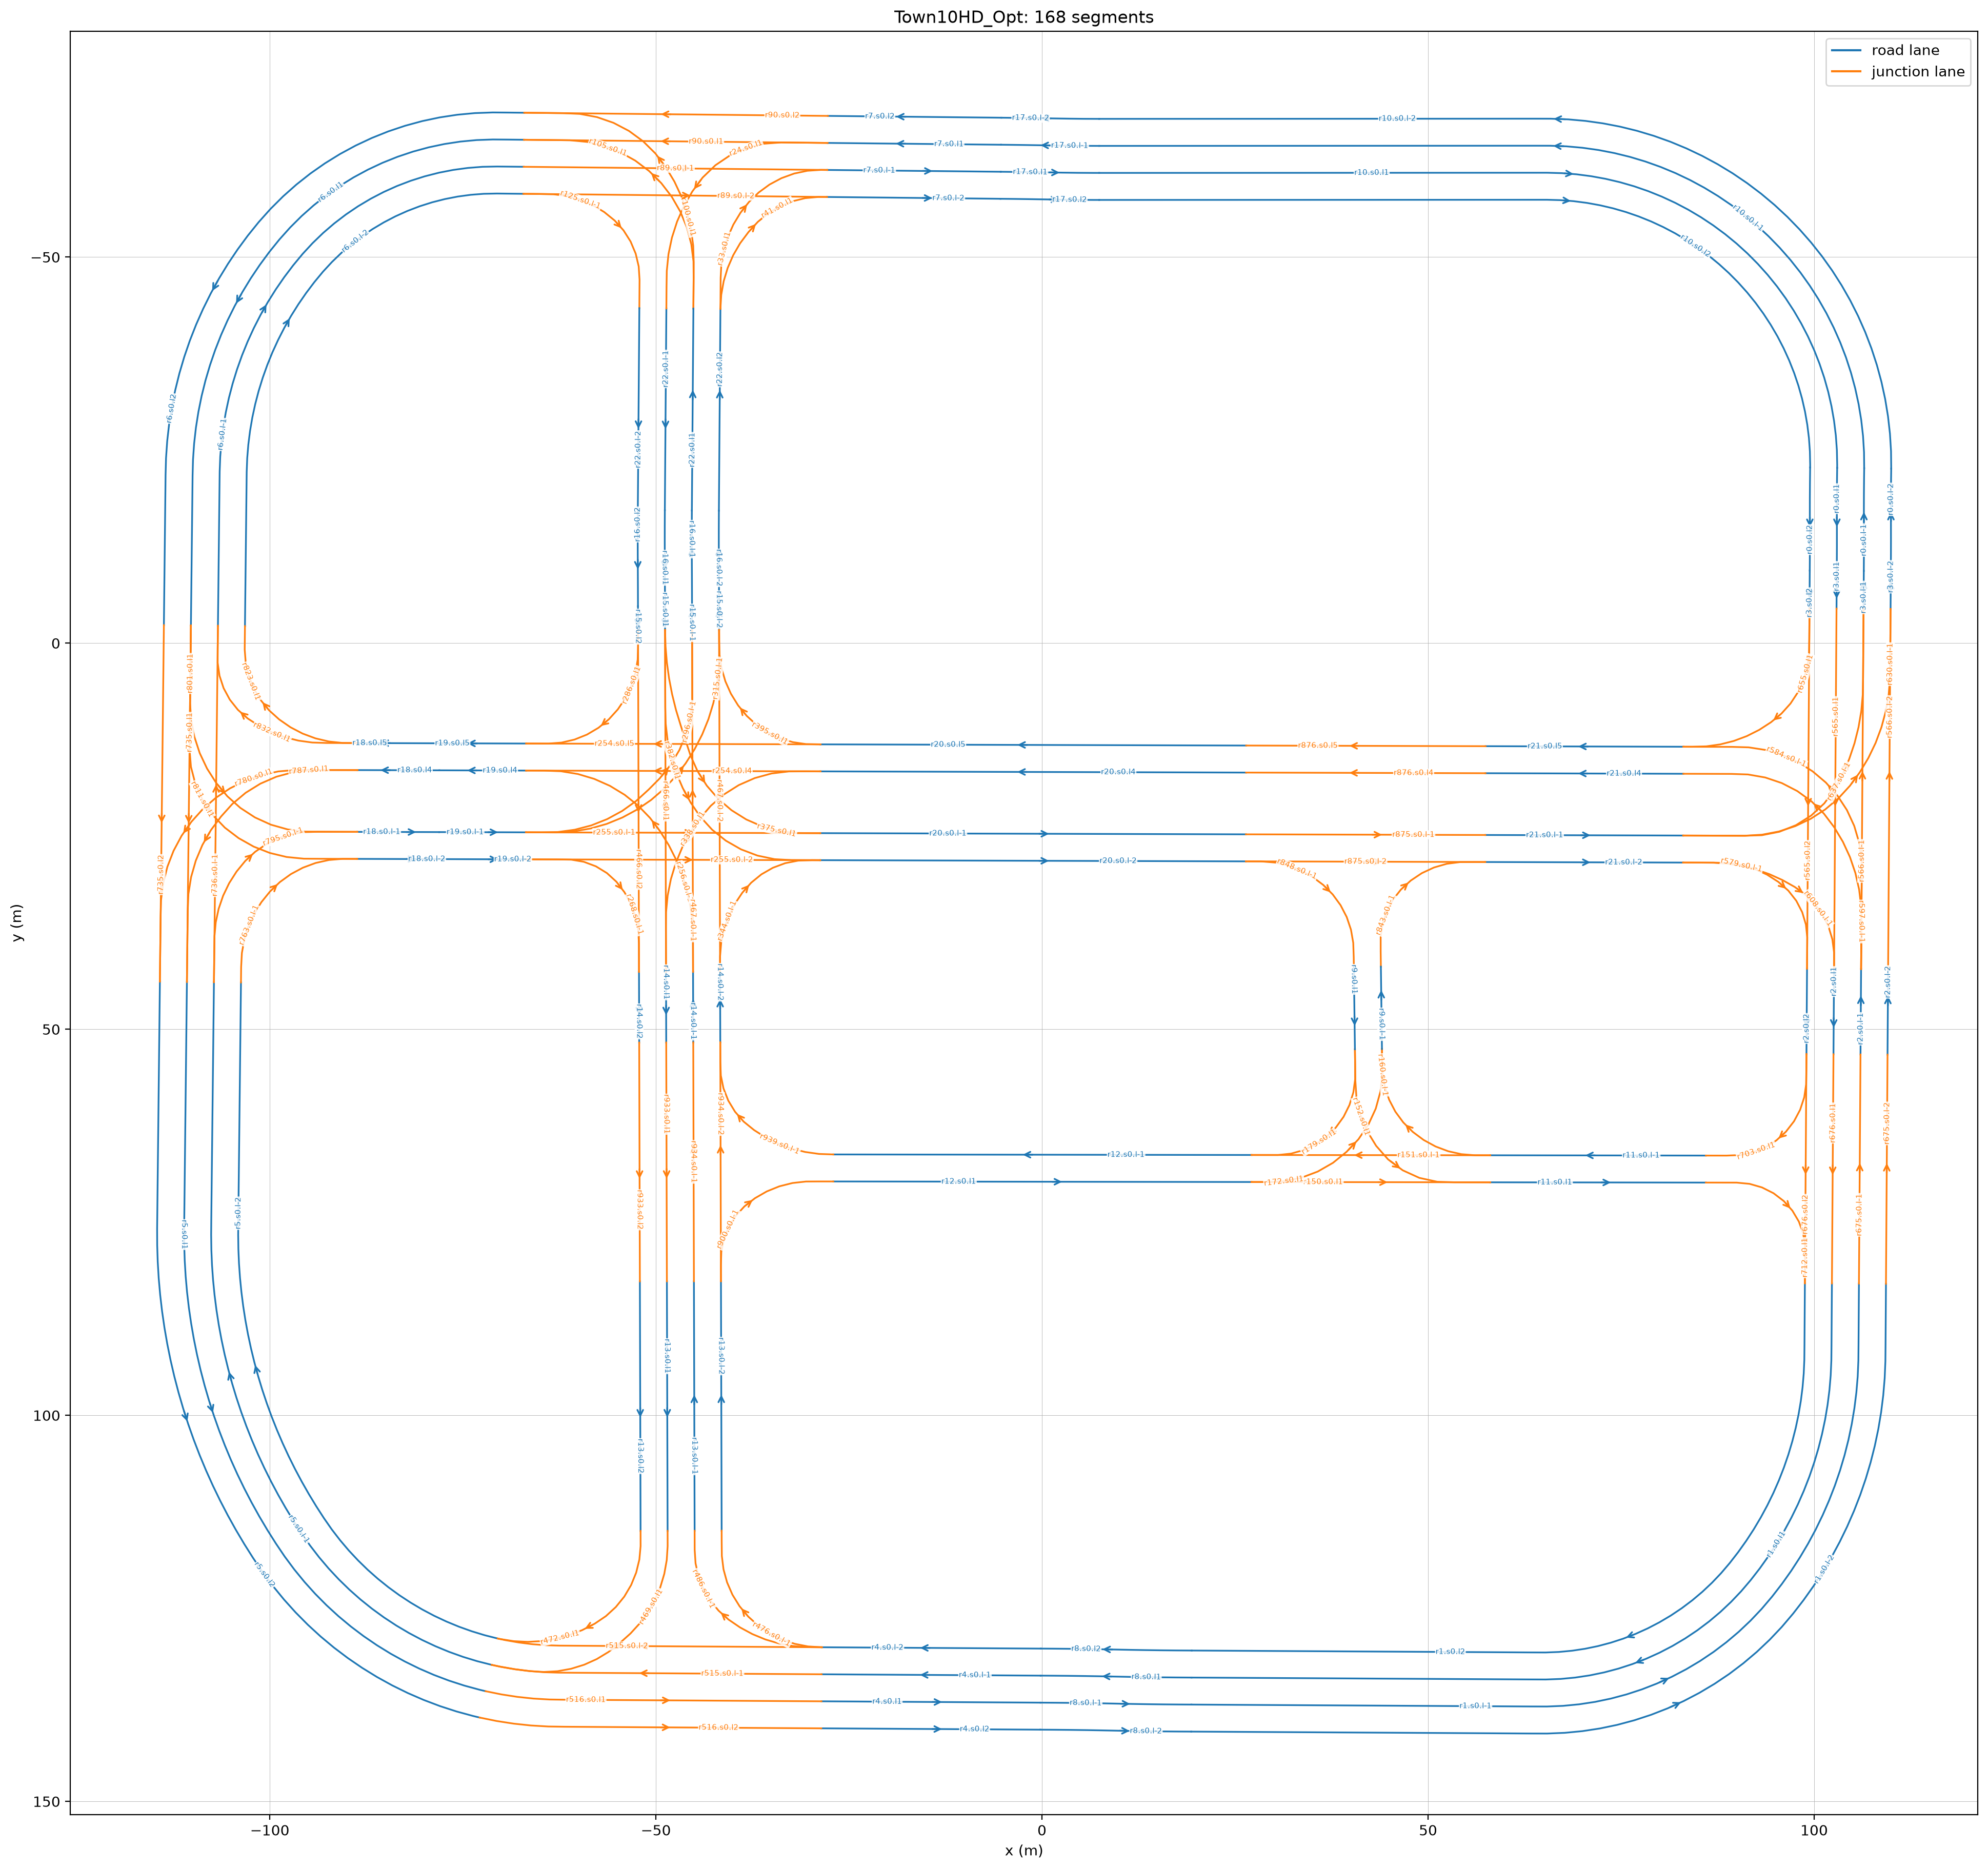

In [4]:
LABEL_SEGMENTS = True
SHOW_JUNCTIONS = True

figure = World.view_topology(wrg, label_segments=LABEL_SEGMENTS, show_junctions=SHOW_JUNCTIONS)
figure.savefig(OUTPUT / "town10-topology.png", bbox_inches="tight")

## Segments

In [5]:
segment = wrg.get_segment("r296.s0.l-1")

print(f"{segment.id}: {segment.length_m:.1f} m, limit {segment.speed_limit_kmh:g} km/h")
print("leads to:", ", ".join(segment.successors))
print("midpoint (x, y, z):", tuple(round(v, 2) for v in segment.point_at(segment.length_m / 2)))

r296.s0.l-1: 39.7 m, limit 30 km/h
leads to: r15.s0.l-1
midpoint (x, y, z): (-49.24, 17.19, 0.0)


## Junctions

A junction is an intersection declared by the map. Each segment inside one carries its `junction_id`, and the junction has a bounding box in meters.

In [ ]:
print(f"{segment.id} is in junction {segment.junction_id}")

for junction in wrg.get_junctions():
    lanes = wrg.segments_in_junction(junction.id)
    print(f"junction {junction.id:4}: {len(lanes):2} lanes, center ({junction.x:7.1f}, {junction.y:7.1f}), "
          f"{2 * junction.extent_x:.0f} m x {2 * junction.extent_y:.0f} m")

## Assign Hazard Probabilities

Each segment holds one probability per hazard. Assigning the same hazard again replaces its value.

In [6]:
segment.assign_hazard_probability([
    (hazards.pedestrian, 0.03),  # event: chance per second that one starts
    (hazards.wet_road, 0.4),     # condition: chance that it holds for the run
])

segment.hazard_probabilities

[HazardProbability(hazard_id='pedestrian', probability=0.03),
 HazardProbability(hazard_id='wet_road', probability=0.4)]

## Save and Load

In [7]:
path = OUTPUT / "town10-world.json.gz"
wrg.save(path)

wrg = WorldRoadGraph.load(path)
for item in wrg.get_segment("r296.s0.l-1").hazard_probabilities:
    print(f"{item.hazard_id} ({hazards.get(item.hazard_id).kind.value}): {item.probability}")

pedestrian (event): 0.03
wet_road (condition): 0.4
